# Моделі без Timestral: сонячний час і нормування на потужність

Мета: перевірити сімейство моделей, яке не залежить від Timestral, на тих самих вікнах, що й решта проєкту: 11 вікон відбору (3–25 жовтня) і одне вікно аудиту (25–27 жовтня). Погодні сценарії спільні. 30 раніших вікон використано лише для калібрування інтервалів.

Ноутбук читає збережені результати з `results/sun/`, тож перенавчання не потрібне. Kernel: `Time Series (.venv)`.

Щоб перерахувати все з нуля (потрібні результати попередніх кроків проєкту):

```bash
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=7 .venv/bin/python scripts/session1_sun_fit.py
.venv/bin/python scripts/session1_sun_evaluate.py
.venv/bin/python scripts/session1_sun_final.py
```

In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd()/'scripts'))

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 180, 'display.max_columns', 30, 'display.max_rows', 60)
plt.rcParams.update({'figure.figsize': (12, 4.6), 'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True})
BLUE, ORANGE, AQUA, YELLOW, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#52514e'
OUT = Path('results/sun')
data = pd.read_csv('train.csv', parse_dates=['ds'])
z = np.load(OUT/'points.npz')
origins = z['origins']; y = data.y.to_numpy(float)
A = np.stack([y[o:o+48] for o in origins[:-1]])
print('вікон для калібрування і перевірки:', len(A), '| останнє вікно закінчується', data.ds.iloc[-1])

вікон для калібрування і перевірки: 48 | останнє вікно закінчується 2026-10-27 00:00:00


## 1. Що показує ряд

Генерація — це сонце плюс вітер. Рівень за рік виріс у кілька разів, тому модель, яка навчається на сирому `y` за довгу історію, бачить переважно менші значення з минулого. Тут ціль ділиться на оцінку поточної потужності, яку рахують лише за даними до початку прогнозу.

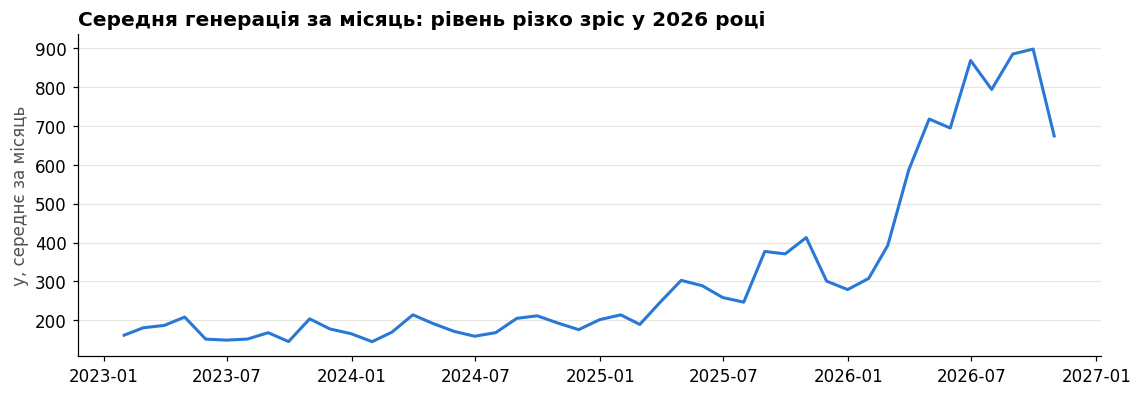

In [2]:
m = data.set_index('ds').y.resample('M').mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(m.index, m.values, color=BLUE, lw=2)
ax.set_title('Середня генерація за місяць: рівень різко зріс у 2026 році', loc='left', fontweight='bold')
ax.set_ylabel('y, середнє за місяць', color=MUTED)
ax.grid(axis='x', visible=False)
plt.show()

## 2. Моделі

Усі моделі прямі: прогнозують 48 годин одразу, а ознаки беруть лише те, що відомо на момент прогнозу. Сонце описується положенням відносно сходу й заходу (за колонкою `daylight`), а не годинником.

| Назва | Що це |
|---|---|
| `gbm_sun`, `gbm_sun_med` | Бустинг (HistGradientBoosting) на цілі, нормованій на плавну шкалу день/ніч, за 730 днів; `_med` — медіанна втрата |
| `phys`, `phys_med` | Декомпозиція: монотонна крива вітру на нічних годинах плюс модель сонця на залишку |
| `analog` | kNN: 60 найсхожіших погодних годин у нормованому просторі |
| `decay_ridge` | Ridge на сирому `y` з вагами, що згасають із періодом напіврозпаду 45 днів |
| `sun_snaive` | SNaive із вирівнюванням за сонячним часом |
| `med4_snaive10` | **Кандидат:** середнє `gbm_sun_med`, `phys_med`, `analog`, `decay_ridge`, 90%, плюс 10% SNaive |
| `gbmphysmed_snaive20` | Середнє двох медіанних моделей, 80%, плюс 20% SNaive |

## 3. Точкові прогнози

Сценарії з похибками погоди, 11 вікон відбору. `RMSE` — усі 48 годин, `d2_` — другий день, за яким рахують фінальний ранг, `wins` — перемоги над SNaive із 11, `aud` — вікно аудиту.

In [3]:
scores = pd.read_csv(OUT/'point_scores.csv')
refs = pd.DataFrame([dict(model='REF бленд проєкту (з Timestral)', RMSE=232.55, d2_RMSE=249.17, d2_MAPE=189.30, wins=10, aud=179.85),
                     dict(model='REF Timestral-28M', RMSE=240.79, d2_RMSE=260.66, d2_MAPE=168.13, wins=9, aud=180.14)])
cols = ['model', 'RMSE', 'd2_RMSE', 'd2_MAPE', 'wins', 'aud', 'aud_d2']
pd.concat([refs, scores.drop_duplicates('RMSE')], ignore_index=True).sort_values('RMSE')[cols].reset_index(drop=True)

,model,RMSE,d2_RMSE,d2_MAPE,wins,aud,aud_d2
0,REF бленд проєкту (з Timestral),232.55,249.17,189.30,10,179.85,NaN
1,REF Timestral-28M,240.79,260.66,168.13,9,180.14,NaN
2,med4_75_chronos_sarima,251.77,261.68,212.88,10,113.67,105.36
3,med4_50_chronos_sarima,252.27,274.52,221.46,9,113.64,89.45
4,gbmphysmed_snaive20,256.31,266.06,207.91,10,92.12,101.14
5,med4_snaive10,258.88,258.28,212.24,10,114.85,115.70
6,gbm_sun_med,263.24,275.53,192.92,10,143.89,154.96
7,decay_ridge,265.25,262.97,237.41,10,146.47,148.10
8,mean_med4,267.39,261.83,205.47,9,125.04,127.02
9,mean_new4,273.40,267.43,223.48,9,143.52,133.06


Жодна модель без Timestral не наздогнала Timestral на вікнах відбору. Зате чимало з них обіграли SNaive на аудиті, чого не вдалося Timestral. Аудит — це одне вікно, яке вже бачили раніше, тому це слабкий сигнал.

## 4. Вікно за вікном

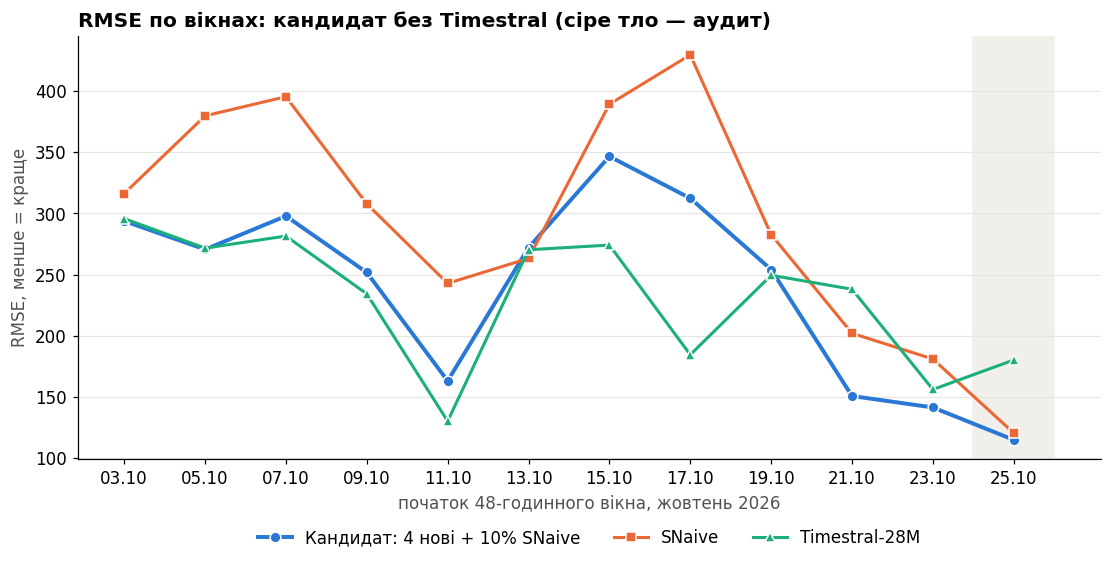

перемоги кандидата над SNaive: 10 із 11; над Timestral: 4 із 11


In [4]:
ST = [1, 2, 3]
sn = z['snaive'][:49]
cand = .9*(z['gbm_sun_med'][:49]+z['phys_med'][:49]+z['analog'][:49]+z['decay_ridge'][:49])/4+.1*sn
win = lambda p: np.sqrt(((p[36:48, :, :]-A[36:48, None])[:, ST]**2).mean(axis=(1, 2)))
t = pd.read_csv('results/timestral/window_comparison.csv')
t = t[(t.scenario == 'weather_stress') & (t.model == 'timestral_28m_weather_504h')].sort_values('fold')
ser = [('Кандидат: 4 нові + 10% SNaive', win(cand), BLUE, 'o', 2.6), ('SNaive', win(sn), ORANGE, 's', 2),
       ('Timestral-28M', t.RMSE.to_numpy(), AQUA, '^', 2)]
days = [data.ds.iloc[o] for o in origins[36:48]]
lab = [f'{d:%d.%m}' for d in days]
fig, ax = plt.subplots(figsize=(12, 5))
ax.axvspan(10.5, 11.5, color='#f0efea', zorder=0); ax.text(11, ax.get_ylim()[1], '', ha='center')
for n, v, c, mk, w in ser:
    ax.plot(range(12), v, color=c, marker=mk, ms=7, lw=w, label=n, mec='white', mew=1)
ax.set_xticks(range(12)); ax.set_xticklabels(lab)
ax.set_title('RMSE по вікнах: кандидат без Timestral (сіре тло — аудит)', loc='left', fontweight='bold')
ax.set_xlabel('початок 48-годинного вікна, жовтень 2026', color=MUTED); ax.set_ylabel('RMSE, менше = краще', color=MUTED)
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(.5, -.13)); ax.grid(axis='x', visible=False)
plt.show()
print('перемоги кандидата над SNaive:', (win(cand)[:11] < win(sn)[:11]).sum(), 'із 11; над Timestral:', (win(cand)[:11] < t.RMSE.to_numpy()[:11]).sum(), 'із 11')

## 5. Перехід годинника

Прапорець `daylight` стрибком зсувається на годину 27 жовтня, тобто на початку прогнозу. У вікнах валідації такого зсуву немає, тому я окремо перевірила минулі події: RMSE за 48 годин, що починаються в день зсуву.

In [5]:
ev = pd.read_csv(OUT/'clock_events.csv').set_index('model')
ev.loc[['med4_snaive10', 'gbmphysmed_snaive20', 'snaive', 'sun_snaive'], ['2024-10-27', '2025-03-31', '2025-10-27', '2026-03-31', 'mean_ratio_vs_snaive']]

,2024-10-27,2025-03-31,2025-10-27,2026-03-31,mean_ratio_vs_snaive
model,,,,,
med4_snaive10,59.45,70.68,156.33,278.24,0.95
gbmphysmed_snaive20,62.77,73.35,167.07,262.98,0.96
snaive,72.33,198.81,148.86,177.52,1.00
sun_snaive,77.35,216.86,171.63,221.09,1.14


SNaive у сонячному часі гірший за звичайний: у середньому на 14% і на всіх 4 подіях за 48 годин. На другому дні окремо він кращий у 2 подіях із 4. Отже, гіпотеза, що простий зсув профілю дає виграш, **не підтвердилася**. У березні 2026 моделі сильно програють SNaive. Тому у фінальному бленді взято звичайний SNaive.

## 6. Інтервали

Інтервал калібрується лише на вікнах, що передують поточному. Варіанти: одна ширина на день (`absolute_day`), окрема ширина для ночі, сутінків і піку (`tier`), лише останні 16 вікон (`tier_recent16`), масштабування старих похибок під поточний рівень (`level`, `tier_level`) і половинне масштабування (`recent_half_level`).

`W_d2` — Winkler другого дня на 11 вікнах відбору, `aud_W_d2` — на аудиті, `fut_w_d2` — ширина майбутнього інтервалу. Для порівняння: у Timestral `W_d2` = 1142.90.

In [6]:
iv = pd.read_csv(OUT/'final_intervals.csv')
iv[iv.model == 'four_new_snaive10'][['interval', 'W_d2', 'cov_d2', 'width_d2', 'aud_W_d2', 'fut_w_d1', 'fut_w_d2']].sort_values('W_d2').reset_index(drop=True)

,interval,W_d2,cov_d2,width_d2,aud_W_d2,fut_w_d1,fut_w_d2
0,tier_recent16,1271.750,0.936,870.228,808.965,755.165,778.467
1,tier,1284.828,0.913,795.437,735.323,691.561,701.266
2,recent_half_level,1285.972,0.927,835.974,636.232,547.641,554.796
3,absolute_day,1309.284,0.917,827.759,763.955,683.263,729.357
4,tier_level,1335.661,0.900,736.838,499.881,341.799,350.169
5,level,1419.676,0.891,740.316,458.390,367.667,358.774


Обрано `recent_half_level`: Winkler на відборі майже такий самий, як у найкращого варіанта (приблизно на 1% гірший), а на аудиті значно кращий. Повне масштабування відкинуто: на відборі Winkler помітно зростає, а покриття падає до 89–90%.

Інтервал усе одно гірший за Timestral на 11 вікнах. Вибір спирається на те, що зараз рівень генерації низький, і на незалежність від Timestral, а не на загальну перевагу.

## 7. Прогноз на 48 годин

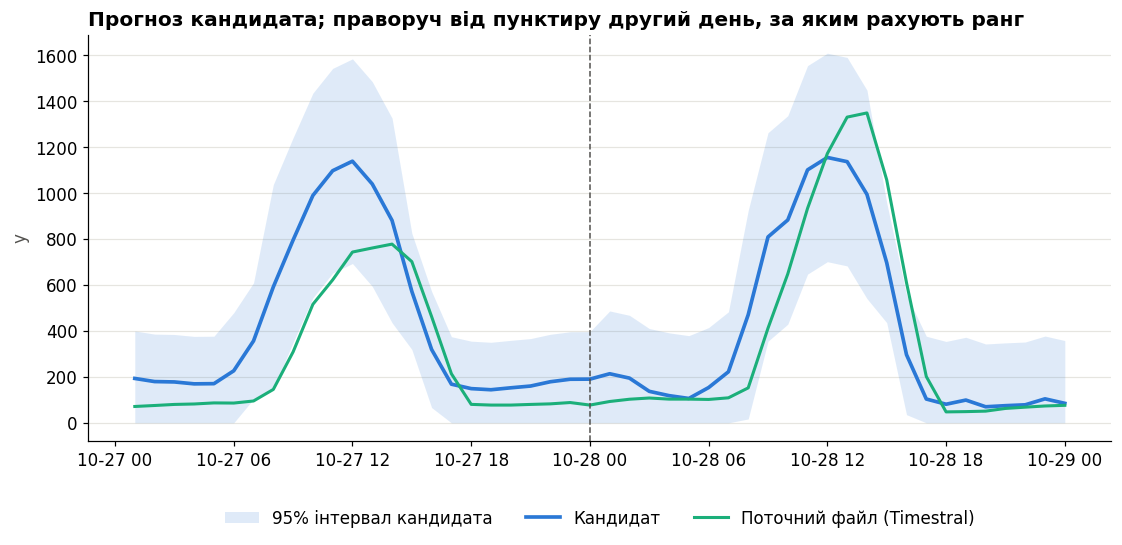

,день,середнє,ширина кандидата,ширина поточного
0,1,426.4,547.6,680.2
1,2,391.1,554.8,740.8


In [7]:
f = pd.read_csv(OUT/'candidate_final_four_new_half_level.csv', parse_dates=['ds'])
cur = pd.read_csv('NAZARENKO_project.csv', parse_dates=['ds'])
assert list(f.columns) == ['ds', 'forecast', 'lower_95', 'upper_95'] and len(f) == 48
assert (f.lower_95 >= 0).all() and (f.lower_95 <= f.forecast).all() and (f.forecast <= f.upper_95).all()
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.fill_between(f.ds, f.lower_95, f.upper_95, color=BLUE, alpha=.15, lw=0, label='95% інтервал кандидата')
ax.plot(f.ds, f.forecast, color=BLUE, lw=2.4, label='Кандидат')
ax.plot(cur.ds, cur.forecast, color=AQUA, lw=2, label='Поточний файл (Timestral)')
ax.axvline(f.ds.iloc[23], color=MUTED, lw=1, ls='--')
ax.set_title('Прогноз кандидата; праворуч від пунктиру другий день, за яким рахують ранг', loc='left', fontweight='bold')
ax.set_ylabel('y', color=MUTED); ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(.5, -.13)); ax.grid(axis='x', visible=False)
plt.show()
pd.DataFrame({'день': ['1', '2'], 'середнє': [f.forecast[:24].mean(), f.forecast[24:].mean()],
              'ширина кандидата': [(f.upper_95-f.lower_95)[:24].mean(), (f.upper_95-f.lower_95)[24:].mean()],
              'ширина поточного': [(cur.upper_95-cur.lower_95)[:24].mean(), (cur.upper_95-cur.lower_95)[24:].mean()]}).round(1)

## 8. Обмеження

- Вікна відбору використовувалися багато разів, тому невеликі різниці між кандидатами — переважно шум.
- Аудит — одне вікно, яке вже бачили раніше.
- Похибки погоди в сценаріях гіпотетичні.
- Інтервали вибрано на тих самих вікнах, тому незалежної перевірки покриття немає.
- Вузький інтервал вразливий до різкого стрибка генерації: штраф за промах 40-кратний.
- Простий зсув за сонячним часом не дав виграшу на минулих переходах годинника.